V26B.ART Artifact Classification DL Model
Developed by M. Chaney, 2026

In [21]:
import os
import cv2
import matplotlib.pyplot as plt
import random
from PIL import Image
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import joblib
from tqdm import tqdm

In [14]:
# folder paths
dataset_path = r'C:/Users/Owner/Documents/Lagoon_Public_Art_V26B/Photos/Condition_Assessment'

# training directory
train_dir = os.path.join(dataset_path, 'Train')

# file names
classes = os.listdir(train_dir)

In [15]:
transform = transforms.Compose([
	transforms.Resize((400,400)),
	transforms.ToTensor(),
])

In [27]:
train_dataset = ImageFolder(os.path.join(dataset_path, 'Train/BC_Data'), transform = transform)
val_dataset = ImageFolder(os.path.join(dataset_path, 'Val'), transform = transform)
test_dataset = ImageFolder(os.path.join(dataset_path, 'Test'), transform = transform)

train_loader = DataLoader(train_dataset, batch_size = 32, shuffle = True, num_workers = 0)
val_loader = DataLoader(val_dataset, batch_size = 16, shuffle = False)
test_loader = DataLoader(test_dataset, batch_size = 16, shuffle = False)

In [28]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # works with nvidia gpus

## make sure these two match
resnet_num = '50'
model = models.resnet50(pretrained = True)

for param in model.parameters():
	param.requires_grad = False

num_classes = len(train_dataset.classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)

## find a way to add more layers to the top	

model = model.to(device)

optimizer = optim.Adam(model.parameters(), lr = 0.001)
criterion = nn.CrossEntropyLoss()

c:\Users\Owner\anaconda3\envs\PubArt\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Owner\anaconda3\envs\PubArt\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [29]:
def train_one_epoch(model, loader):
	model.train()
	running_loss = 0

	for images, labels in loader:
		images, labels = images.to(device), labels.to(device)
		optimizer.zero_grad()
		outputs = model(images)
		loss = criterion(outputs, labels)
		loss.backward()
		optimizer.step()
		running_loss += loss.item()

	return running_loss / len(loader)

In [30]:
def evaluate(model, loader): 
	model.eval()
	correct = 0
	total = 0

	with torch.no_grad():
		for images, labels in loader:
			images, labels = images.to(device), labels.to(device)
			outputs = model(images)
			_, predicted = torch.max(outputs.data, 1)
			total += labels.size(0)
			correct += (predicted == labels).sum().item()

	return correct / total

In [31]:
epochs = 2
for epoch in tqdm(range(epochs)):
	train_loss = train_one_epoch(model, train_loader)
	val_acc = evaluate(model, val_loader)
	print(f"Epoch {epoch + 1}, Train Loss: {train_loss:.4f}, Validation Accuracy: {val_acc:.4f}")

 50%|█████     | 1/2 [02:57<02:57, 177.62s/it]

Epoch 1, Train Loss: 1.5587, Validation Accuracy: 0.6229


100%|██████████| 2/2 [05:52<00:00, 176.32s/it]

Epoch 2, Train Loss: 1.4436, Validation Accuracy: 0.0596


In [32]:
test_acc = evaluate(model, test_loader)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.0596


In [33]:
def visualize_predictions(model, loader, n=5):
    model.eval
    images_shown = 0
    class_names = train_dataset.classes

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(n):
                img = images[i].cpu().permute(1,2,0).numpy()
                plt.imshow((img))
                plt.title(f'True: {class_names[labels[i]]}, Pred: {class_names[preds[i]]}')
                plt.axis('off')
                plt.show()

                images_shown += 1

                if images_shown >= n:
                    return

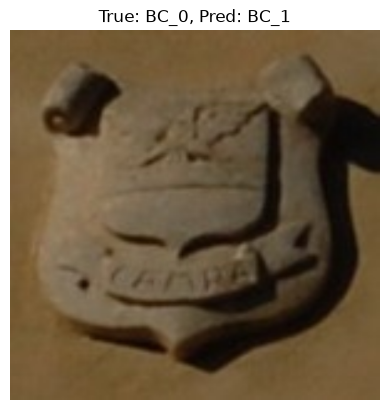

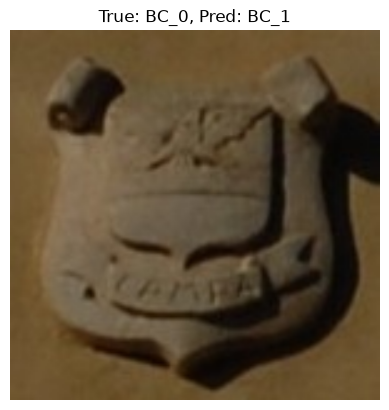

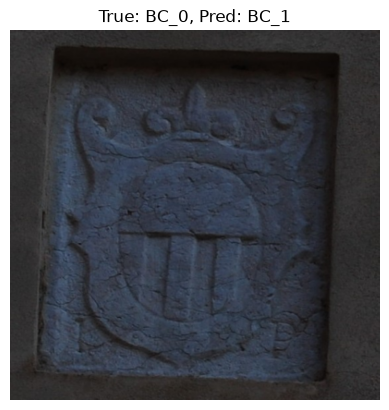

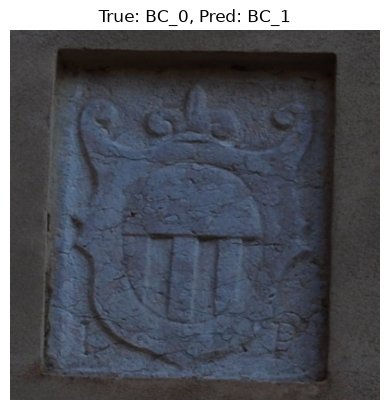

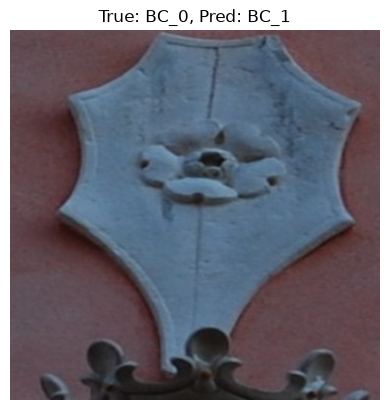

In [34]:
visualize_predictions(model, test_loader, 5)

In [ ]:
model_data = {
    'model_state_dict' : model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx
}

In [ ]:
joblib.dump(model_data, f'condition_assessment_model_resnet{resnet_num}.pkl')